# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: the EMT-TF expression step is **unconditional** — always the
last notebook regardless of the gate outcome. Gate 2 = NO-GO stopped the gate chain
after 03, so the branching-only correlation/modules notebooks are not produced and this
expression notebook follows signatures directly, numbered 04 per §6.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking
the ends of its trajectory. Per the **derive-don't-inherit** mandate we do **not**
inherit that pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist
factors **plus the mesenchymal/neural-crest FOXC and PRRX families** — along *this*
trajectory, gate on detectable expression (3% floor), and let the data choose the most
end-specific factor at each end. VIM (vimentin) is a mesenchymal *marker*, not a TF, and
is excluded. The categorical overlay (thresholded expressers on a grey manifold) follows
the reference plotting style, with a display cutoff so the panel is not outlier-washed.
Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 64399 | pseudotime range 0.0 -> 10.38


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early
(root) vs late (terminus) pseudotime tercile, and Spearman correlation with pseudotime.
Most negative correlation (sufficiently expressed) marks the root end; most positive
marks the terminus. Factors below a 3% expression floor are too sparse to overlay.

In [6]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX1      0.021       0.028      0.022    -0.039    EARLY(root)
 PRRX2      0.042       0.052      0.041    -0.037    EARLY(root)
  ZEB1      0.157       0.187      0.212    -0.010 LATE(terminus)
 FOXC2      0.004       0.004      0.004    -0.006 LATE(terminus)
 FOXC1      0.036       0.039      0.046    -0.005 LATE(terminus)
 SNAI1      0.001       0.000      0.001     0.004 LATE(terminus)
TWIST2      0.001       0.001      0.002     0.006 LATE(terminus)
TWIST1      0.001       0.001      0.002     0.015 LATE(terminus)
  ZEB2      0.020       0.014      0.032     0.026 LATE(terminus)
 SNAI2      0.021       0.012      0.038     0.067 LATE(terminus)

derived pair: PRRX2 (early/root) <-> FOXC1 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right, `size=30`. The abundant late
marker is drawn first so the sparser early marker reads on top. Each factor is
thresholded at the upper quartile of expression among its expressing cells, so only the
strongest expressers show and the early (blue) / late (red) regions separate — a
categorical overlay on the grey manifold, not a continuous single-gene colormap.

overlay thresholds (upper quartile among expressers): {'PRRX2': 1.237, 'FOXC1': 1.309} | cells shown: {'PRRX2': 676, 'FOXC1': 586}
PRRX2: 4.2% expressing; 676 shown (upper quartile), mean pseudotime of shown cells = 0.49 (all cells = 0.41)
FOXC1: 3.6% expressing; 586 shown (upper quartile), mean pseudotime of shown cells = 0.56 (all cells = 0.41)
shown-cell pseudotime separation (PRRX2 vs FOXC1) = 0.07
saved expression.pdf


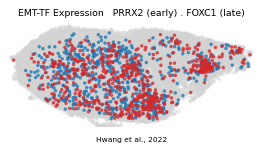

In [8]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')